# Trabalho de estudo de Regressão Logística
## Usando pandas, matplotlib, seaborn, com o dataset Heart Disease Dataset
Link para o dataset = https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset \
A ideia do problema usar a regressão logistica para ver quais variaveis categoricas estão mais relacionadas com alguém estar com crédito inadimplente ou em situação de calote \
Para isso usaremos o dataset menor para fazer um estudo banking_test e depois o banking_train para comparar como a regressão pode mudar conforme o tamanho da base de dados também \
Mais detalhes serão fornecidos na documentação em texto anexa


In [ ]:
# Execute caso para instalar as bibliotecas necessárias no ambiente do Jupyter Notebook
%pip install pandas matplotlib seaborn scikit-learn statsmodels

In [31]:
import pandas as pd
# Carregamento do dataset (substitua pelo caminho correto se necessário)
df = pd.read_csv('heart.csv')
df = df.dropna()

# Exibir as primeiras linhas do DataFrame para teste
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [33]:
import pandas as pd
import numpy as np

# Primeriro tratamento dos dados
# Carregamento do dataset (substitua pelo caminho correto se necessário)
df = pd.read_csv("heart.csv")

# 1. Análise e tratamento das variáveis categóricas
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
# Transformar categorias numéricas em strings para evitar tratamento incorreto
df[categorical_cols] = df[categorical_cols].astype("category")
# One-Hot Encoding (gera variáveis dummys)
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# 2. Análise de assimetria e transformação das variáveis numéricas
numeric_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
# Avaliar assimetria
skews = df_encoded[numeric_cols].skew()
# Aplicar transformação logaritmica somente às variáveis com alta assimetria (> 1)
for col in numeric_cols:
    if abs(skews[col]) > 1:
        df_encoded[col] = np.log1p(df_encoded[col])  # log(1+x)

# 3. Remover valores faltantes (se existirem)
df_encoded = df_encoded.dropna()

# Resultado final
X = df_encoded.drop("target", axis=1)  # variáveis preditoras
y = df_encoded["target"]               # variável resposta binária

print("Formato final da base:", X.shape)
X.head()

Formato final da base: (1025, 22)


,age,trestbps,chol,thalach,oldpeak,sex_1,cp_1,cp_2,cp_3,fbs_1,...,exang_1,slope_1,slope_2,ca_1,ca_2,ca_3,ca_4,thal_1,thal_2,thal_3
0,52,125,5.361292,168,0.693147,True,False,False,False,False,...,False,False,True,False,True,False,False,False,False,True
1,53,140,5.318120,155,1.410987,True,False,False,False,True,...,True,False,False,False,False,False,False,False,False,True
2,70,145,5.164786,125,1.280934,True,False,False,False,False,...,True,False,False,False,False,False,False,False,False,True
3,61,148,5.318120,161,0.000000,True,False,False,False,False,...,False,False,True,True,False,False,False,False,False,True
4,62,138,5.686975,106,1.064711,False,False,False,False,True,...,False,True,False,False,False,True,False,False,True,False


In [36]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.exceptions import ConvergenceWarning
import warnings

# garantir X e y numéricos e consistentes
X_proc = X.copy()
y_proc = y.copy()

# converter y para 0/1 numérico
y_proc = pd.to_numeric(y_proc, errors='coerce')
if y_proc.isna().any():
    raise ValueError("A variável alvo 'y' contém valores não conversíveis para numérico. Verifique.")

# converter X para numérico quando possível (objetos -> NaN)
X_proc = X_proc.apply(pd.to_numeric, errors='coerce')

# remover colunas com NaNs resultantes (ou substituir; aqui removemos)
cols_with_nan = X_proc.columns[X_proc.isna().any()].tolist()
if cols_with_nan:
    print("Removendo colunas com NaN após conversão numérica:", cols_with_nan)
    X_proc = X_proc.drop(columns=cols_with_nan)

# remover colunas constantes (variância zero)
const_cols = [c for c in X_proc.columns if X_proc[c].nunique() <= 1]
if const_cols:
    print("Removendo colunas constantes:", const_cols)
    X_proc = X_proc.drop(columns=const_cols)

# garantir float dtype
X_proc = X_proc.astype(float)
y_proc = y_proc.astype(float)

def stepwise_selection_robust(X, y, initial_list=None,
                              threshold_in=0.05, threshold_out=0.10,
                              verbose=True, max_iter=200):
    if initial_list is None:
        included = []
    else:
        included = list(initial_list)

    # Evitar warnings de convergência poluindo saída
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
    warnings.filterwarnings("ignore", category=FutureWarning)
    warnings.filterwarnings("ignore", category=UserWarning)

    while True:
        changed = False
        # -------------------------
        # Forward step
        # -------------------------
        excluded = list(set(X.columns) - set(included))
        new_pvals = pd.Series(index=excluded, dtype=float)

        for col in excluded:
            cols_try = included + [col]
            try:
                model = sm.Logit(y, sm.add_constant(X[cols_try])).fit(disp=False, maxiter=max_iter)
                # model.pvalues pode não conter 'col' se col linearmente dependente; usar get
                pval = model.pvalues.get(col, np.nan)
            except Exception as e:
                # se ajuste falhar (por singularidade, separação, etc), marcaremos como NaN
                pval = np.nan
            new_pvals[col] = pval

        # escolher melhor candidato com p-value mínimo (não-NaN)
        if new_pvals.dropna().size > 0:
            best_pval = new_pvals.min()
        else:
            best_pval = np.nan

        if not np.isnan(best_pval) and best_pval < threshold_in:
            best_feature = new_pvals.idxmin()
            included.append(best_feature)
            changed = True
            if verbose:
                print(f"🔹 Entrada: {best_feature} (p={best_pval:.4f})")
        # -------------------------
        # Backward step
        # -------------------------
        if len(included) > 0:
            try:
                model = sm.Logit(y, sm.add_constant(X[included])).fit(disp=False, maxiter=max_iter)
                pvalues = model.pvalues.iloc[1:]  # excluir const
            except Exception as e:
                # se ajuste falhar, interromper remoção (não confiamos nos p-values)
                pvalues = pd.Series(index=included, data=np.nan)

            # remover pior se p > threshold_out
            if pvalues.dropna().size > 0:
                worst_pval = pvalues.max()
                if worst_pval > threshold_out:
                    worst_feature = pvalues.idxmax()
                    included.remove(worst_feature)
                    changed = True
                    if verbose:
                        print(f"🔻 Remoção: {worst_feature} (p={worst_pval:.4f})")

        if not changed:
            break

    return included

# rodar seleção
selected = stepwise_selection_robust(X_proc, y_proc, verbose=True)
print("\nVariáveis selecionadas (robusto):", selected)


🔹 Entrada: thal_2 (p=0.0000)
🔹 Entrada: exang_1 (p=0.0000)
🔹 Entrada: oldpeak (p=0.0000)
🔹 Entrada: ca_1 (p=0.0000)
🔹 Entrada: ca_2 (p=0.0000)
🔹 Entrada: ca_3 (p=0.0000)
🔹 Entrada: cp_2 (p=0.0000)
🔹 Entrada: slope_1 (p=0.0000)
🔹 Entrada: cp_3 (p=0.0000)
🔹 Entrada: sex_1 (p=0.0000)
🔹 Entrada: thal_1 (p=0.0001)
🔹 Entrada: trestbps (p=0.0002)
🔹 Entrada: cp_1 (p=0.0003)
🔹 Entrada: thalach (p=0.0088)
🔹 Entrada: restecg_1 (p=0.0168)

Variáveis selecionadas (robusto): ['thal_2', 'exang_1', 'oldpeak', 'ca_1', 'ca_2', 'ca_3', 'cp_2', 'slope_1', 'cp_3', 'sex_1', 'thal_1', 'trestbps', 'cp_1', 'thalach', 'restecg_1']
🔹 Entrada: cp_3 (p=0.0000)
🔹 Entrada: sex_1 (p=0.0000)
🔹 Entrada: thal_1 (p=0.0001)
🔹 Entrada: trestbps (p=0.0002)
🔹 Entrada: cp_1 (p=0.0003)
🔹 Entrada: thalach (p=0.0088)
🔹 Entrada: restecg_1 (p=0.0168)

Variáveis selecionadas (robusto): ['thal_2', 'exang_1', 'oldpeak', 'ca_1', 'ca_2', 'ca_3', 'cp_2', 'slope_1', 'cp_3', 'sex_1', 'thal_1', 'trestbps', 'cp_1', 'thalach', 'restecg_1']


In [38]:
# Modelo final com statsmodels
import statsmodels.api as sm

# X_proc e y_proc são os dados pré-processados usados no stepwise
X_final = X_proc[selected]

# adicionar constante
X_final_const = sm.add_constant(X_final)

# ajustar o modelo
logit_model = sm.Logit(y_proc, X_final_const).fit()

print(logit_model.summary())


Optimization terminated successfully.
         Current function value: 0.306124
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:                 1025
Model:                          Logit   Df Residuals:                     1009
Method:                           MLE   Df Model:                           15
Date:                Fri, 05 Dec 2025   Pseudo R-squ.:                  0.5581
Time:                        18:47:51   Log-Likelihood:                -313.78
converged:                       True   LL-Null:                       -710.12
Covariance Type:            nonrobust   LLR p-value:                3.111e-159
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.0313      1.233      1.647      0.099      -0.385       4.448
thal_2         1.4248      0.

In [39]:
# Cruva ROC + Calculo do threshold ótimo
import numpy as np
from sklearn.metrics import roc_curve, auc

y_pred_prob = logit_model.predict(X_final_const)

fpr, tpr, thresholds = roc_curve(y_proc, y_pred_prob)
roc_auc = auc(fpr, tpr)

print("AUC =", roc_auc)

youden_J = tpr - fpr
best_index = np.argmax(youden_J)
best_threshold = thresholds[best_index]

print("Melhor threshold (Youden J):", best_threshold)
print("TPR =", tpr[best_index], "FPR =", fpr[best_index])

AUC = 0.9422342784428173
Melhor threshold (Youden J): 0.4446608214780097
TPR = 0.9296577946768061 FPR = 0.17234468937875752


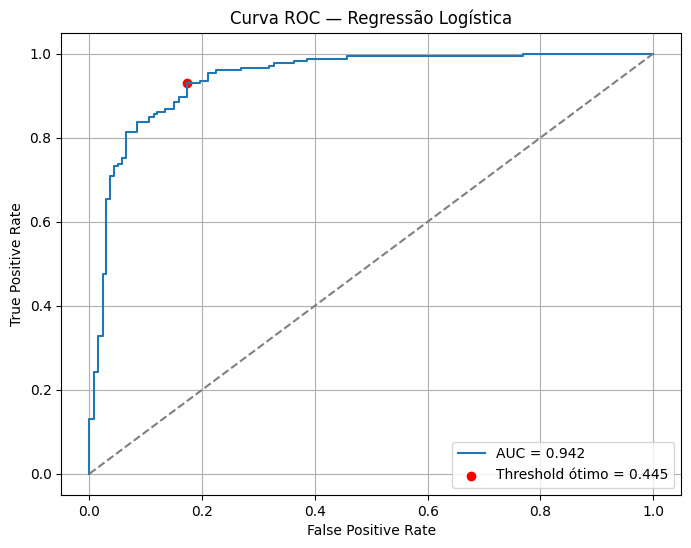

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')  # linha aleatória
plt.scatter(fpr[best_index], tpr[best_index], c='red', label=f"Threshold ótimo = {best_threshold:.3f}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC — Regressão Logística")
plt.legend()
plt.grid(True)
plt.show()


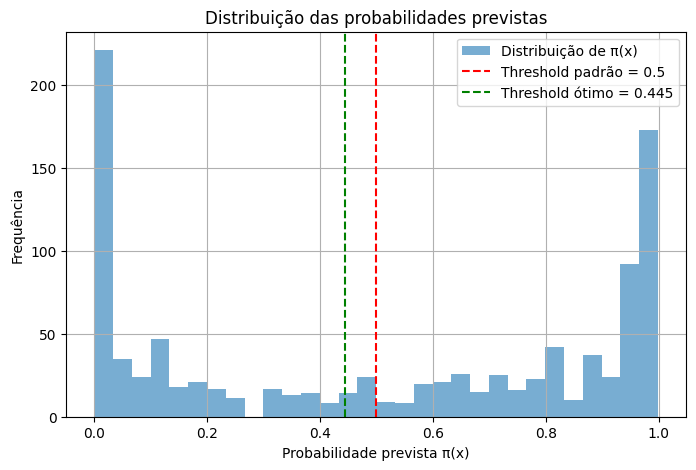

In [41]:
plt.figure(figsize=(8, 5))
plt.hist(y_pred_prob, bins=30, alpha=0.6, label="Distribuição de π(x)")
plt.axvline(0.5, color='red', linestyle='--', label="Threshold padrão = 0.5")
plt.axvline(best_threshold, color='green', linestyle='--', label=f"Threshold ótimo = {best_threshold:.3f}")
plt.xlabel("Probabilidade prevista π(x)")
plt.ylabel("Frequência")
plt.title("Distribuição das probabilidades previstas")
plt.legend()
plt.grid(True)
plt.show()

In [64]:
# -------------------------
# Recalcular threshold ótimo de forma robusta e plotar matrizes
# -------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc

# --- Garantias / recomputar ROC se necessário ---
# Pressupostos: y_proc (true labels) e y_pred_prob (probabilidades previstas) existem.
# Se algum não existir, isso levantará NameError — nesse caso rode o ajuste do modelo novamente antes.

# Recalcular fpr,tpr,thresholds se não existirem ou para garantir consistência
fpr, tpr, thresholds = roc_curve(y_proc, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Calcular Youden J e obter índice ótimo (ignora NaNs)
youden = tpr - fpr
# usa nanargmax para robustez
best_idx = int(np.nanargmax(youden))
best_threshold_value = float(thresholds[best_idx])

print(f"AUC = {roc_auc:.4f}")
print(f"Índice ótimo (Youden) = {best_idx}, Threshold ótimo recalculado = {best_threshold_value:.6f}")
print(f"TPR @best = {tpr[best_idx]:.4f}, FPR @best = {fpr[best_idx]:.4f}")

# --- Previsões binárias
y_pred_05 = (y_pred_prob >= 0.5).astype(int)
y_pred_best = (y_pred_prob >= best_threshold_value).astype(int)

# --- Matrizes de confusão
cm_05 = confusion_matrix(y_proc, y_pred_05)
cm_best = confusion_matrix(y_proc, y_pred_best)

# Função de métricas
def metrics_dict(y_true, y_pred):
    return {
        "Acurácia": accuracy_score(y_true, y_pred),
        "Precisão": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

metrics_05 = metrics_dict(y_proc, y_pred_05)
metrics_best = metrics_dict(y_proc, y_pred_best)

# --- Imprimir matrizes e métricas
print("\nMatriz de Confusão (threshold = 0.5):")
print(cm_05)
print("\nMétricas (threshold = 0.5):")
print(metrics_05)

print("\nMatriz de Confusão (threshold ótimo = {:.6f}):".format(best_threshold_value))
print(cm_best)
print("\nMétricas (threshold ótimo):")
print(metrics_best)


AUC = 0.9422
Índice ótimo (Youden) = 85, Threshold ótimo recalculado = 0.444661
TPR @best = 0.9297, FPR @best = 0.1723

Matriz de Confusão (threshold = 0.5):
[[424  75]
 [ 60 466]]

Métricas (threshold = 0.5):
{'Acurácia': 0.8682926829268293, 'Precisão': 0.8613678373382625, 'Recall': 0.8859315589353612, 'F1-score': 0.8734770384254921}

Matriz de Confusão (threshold ótimo = 0.444661):
[[413  86]
 [ 37 489]]

Métricas (threshold ótimo):
{'Acurácia': 0.88, 'Precisão': 0.8504347826086956, 'Recall': 0.9296577946768061, 'F1-score': 0.888283378746594}


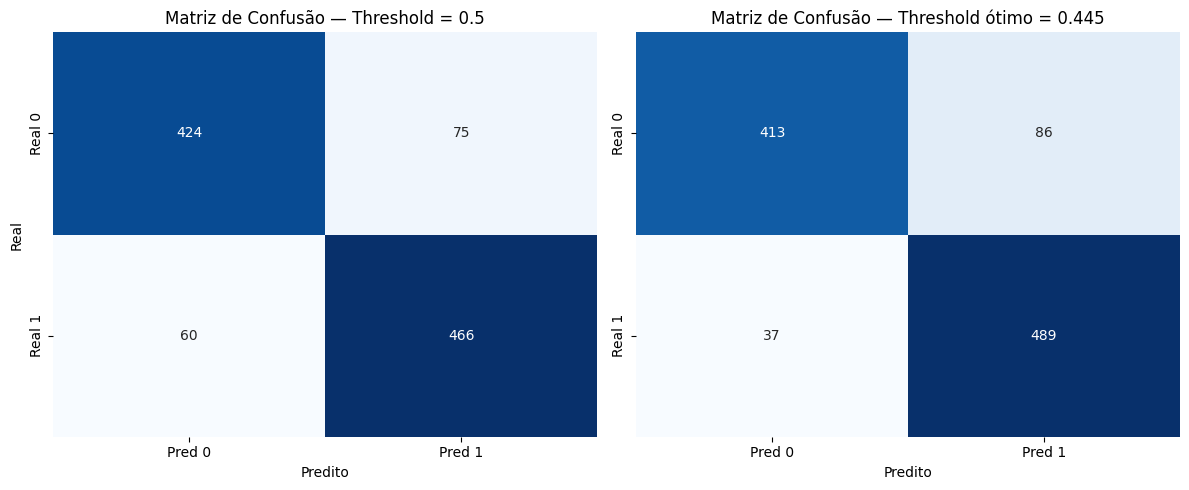

,Acurácia,Precisão,Recall,F1-score
Threshold = 0.5,0.868293,0.861368,0.885932,0.873477
Threshold = 0.444661,0.880000,0.850435,0.929658,0.888283


In [65]:
# --- Plotar lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12,5))

sns.heatmap(cm_05, annot=True, fmt="d", cbar=False, ax=axes[0],
            xticklabels=["Pred 0", "Pred 1"], yticklabels=["Real 0", "Real 1"], cmap="Blues")
axes[0].set_title("Matriz de Confusão — Threshold = 0.5")
axes[0].set_xlabel("Predito")
axes[0].set_ylabel("Real")

sns.heatmap(cm_best, annot=True, fmt="d", cbar=False, ax=axes[1],
            xticklabels=["Pred 0", "Pred 1"], yticklabels=["Real 0", "Real 1"], cmap="Blues")
axes[1].set_title(f"Matriz de Confusão — Threshold ótimo = {best_threshold_value:.3f}")
axes[1].set_xlabel("Predito")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

# --- Tabela comparativa (DataFrame) para relatório
comparison_df = pd.DataFrame([metrics_05, metrics_best], index=["Threshold = 0.5", f"Threshold = {best_threshold_value:.6f}"])
display(comparison_df)

<Figure size 800x500 with 0 Axes>

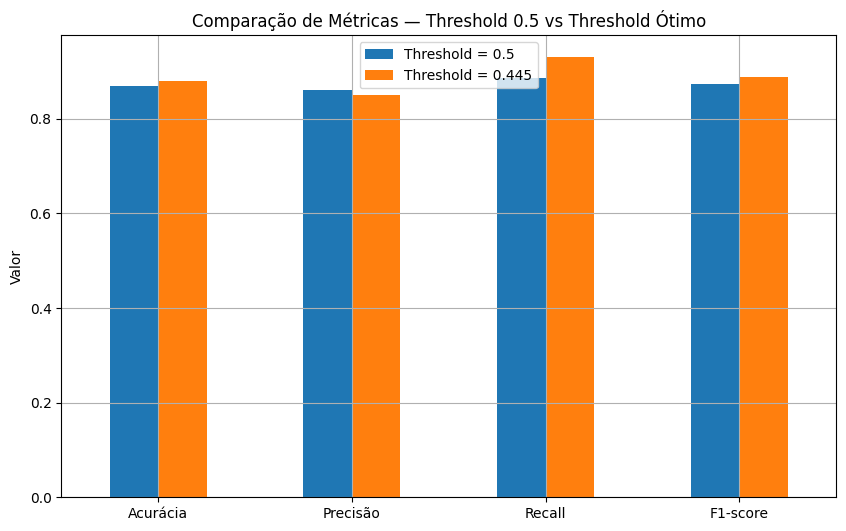

In [43]:
plt.figure(figsize=(8, 5))
comparison_df.T.plot(kind="bar", figsize=(10,6))
plt.title("Comparação de Métricas — Threshold 0.5 vs Threshold Ótimo")
plt.ylabel("Valor")
plt.grid(True)
plt.xticks(rotation=0)
plt.show()


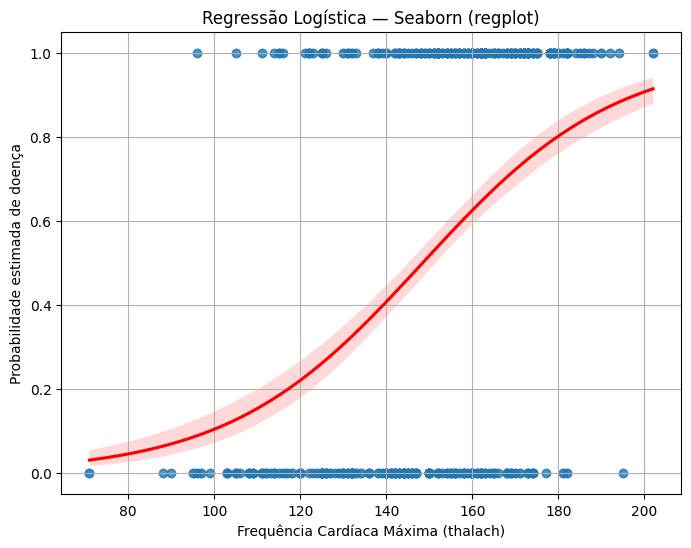

In [44]:
# Por fim o plot da regressão logística usando seaborn
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.regplot(
    x=X_proc['thalach'],       # variável preditora
    y=y_proc,                  # variável binária
    logistic=True,             # ativa regressão logística
    scatter_kws={'alpha':0.4},
    line_kws={'color':'red'}
)

plt.xlabel("Frequência Cardíaca Máxima (thalach)")
plt.ylabel("Probabilidade estimada de doença")
plt.title("Regressão Logística — Seaborn (regplot)")
plt.grid(True)
plt.show()
